# Calculus: integrals and derivatives

Physical models are written with derivatives: a velocity is the derivative of
a position, a position the integral of a velocity. *nnodely* computes them in
two senses:

- **with respect to time**, on sampled signals, with a step `dt`:
  - `DerivativeStep` and `IntegrateStep` act along the **window** of a stream:
    the derivative or the running integral of its samples, in one pass;
  - `Derivative` and `Integrate` act **one step at a time**, in a `ModelyLoop`:
    they keep their past in a state, fed back from step to step;
- **with respect to an input**, exactly, by automatic differentiation:
  `Gradient(wrt=x)` - the derivative of a stream with respect to the `Input`
  `x` - used for sensitivities and physics-informed networks.

`dt` is always given explicitly: windows count samples, not seconds.

In [1]:
import os

# Pick the Keras backend before nnodely (or Keras) is imported:
# "tensorflow" (the default), "torch" or "jax".
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import keras
import matplotlib.pyplot as plt
import numpy as np

from nnodely import (
    DataLoader,
    Derivative,
    DerivativeStep,
    Gradient,
    Input,
    Integrate,
    IntegrateStep,
    Linear,
    Modely,
    ModelyLoop,
    Output,
    Tanh,
    set_seed,
)

set_seed(0)


def run(inputs, outputs, data):
    """Build a model of the given outputs and run it on one batch of data."""
    model = Modely(
        "probe", inputs=inputs, outputs=[Output(k, s) for k, s in outputs.items()]
    ).build()
    results = model(
        {name: np.asarray(value, "float32") for name, value in data.items()}
    )
    return {
        name: keras.ops.convert_to_numpy(value)[0].ravel()
        for name, value in results.items()
    }

## Along a window: `DerivativeStep`

`DerivativeStep(dt)` differentiates each sample of a window with a backward
difference: `(x[i] - x[i-1]) / dt`. The window keeps its length; the first
sample needs the one **before** the window, given as the first argument of the
call, `DerivativeStep(dt)(init, x)` - left out, it is taken as zero.

`poly_order` raises the accuracy: the slope of the polynomial through the last
`poly_order + 1` samples.

In [2]:
dt = 0.1
t = np.arange(40) * dt
x = Input("x", tw=40)
before = Input("before", tw=1)  # the sample just before the window
signal = np.sin(t)

results = run(
    [x, before],
    {
        "order_1": DerivativeStep(dt=dt)(before, x),
        "order_2": DerivativeStep(dt=dt, poly_order=2)(before, x),
        "no_init": DerivativeStep(dt=dt)(x),
    },
    {"x": signal.reshape(1, 40, 1), "before": np.sin(-dt).reshape(1, 1, 1)},
)
exact = np.cos(t)
for name in ("order_1", "order_2"):
    print(
        f"{name}: largest error after the first samples {np.abs(results[name] - exact)[3:].max():.4f}"
    )
print(
    "without init, the first sample is",
    results["no_init"][0].round(2),
    "- it takes x[-1] = 0",
)

order_1: largest error after the first samples 0.0500
order_2: largest error after the first samples 0.0033
without init, the first sample is 0.0 - it takes x[-1] = 0


Order 2 is more than ten times more accurate here. But each order amplifies the noise
of measured signals more, and no stencil smooths: filter a noisy signal before
differentiating it.

## Along a window: `IntegrateStep`

`IntegrateStep(dt)` is the running integral of a window, the value just before
the window as the first argument: `y[i] = y[i-1] + dt * r[i]` (`method="euler"`),
or the trapezoid rule, which also takes the rate before the window:
`IntegrateStep(method="trapezoidal", dt)(init, init_rate, rate)`.

Integrated twice, an acceleration window gives the velocity and the position
over the whole window, in one pass:

In [3]:
a = Input("a", tw=40)
v0, p0 = Input("v0", tw=1), Input("p0", tw=1)
velocity = IntegrateStep(dt=dt)(v0, a)
position = IntegrateStep(dt=dt)(p0, velocity)
trapezoid = IntegrateStep(method="trapezoidal", dt=dt)(v0, 0.0, a)

results = run(
    [a, v0, p0],
    {"velocity": velocity, "position": position, "trapezoid": trapezoid},
    {
        "a": np.full((1, 40, 1), 2.0),
        "v0": np.zeros((1, 1, 1)),
        "p0": np.zeros((1, 1, 1)),
    },
)
time = (np.arange(40) + 1) * dt
print(
    "velocity at the end:", results["velocity"][-1].round(3), " exact:", 2.0 * time[-1]
)
print(
    "position at the end:",
    results["position"][-1].round(3),
    " exact:",
    (time[-1] ** 2).round(3),
)
print(
    "trapezoid, first sample:",
    results["trapezoid"][0],
    "- the rate before the window was 0",
)

velocity at the end: 8.0  exact: 8.0
position at the end: 16.4  exact: 16.0
trapezoid, first sample: 0.1 - the rate before the window was 0


The position overshoots the exact 16 a little: Euler's rule holds each rate
constant over its whole step. Euler with `poly_order=1` is the exact inverse of
`DerivativeStep` with the same `init`: differentiating the running integral
gives the rate back.

In [4]:
rate = Input("rate", tw=10)
start = Input("start", tw=1)
round_trip = DerivativeStep(dt=dt)(start, IntegrateStep(dt=dt)(start, rate))
data = {
    "rate": np.random.default_rng(0).normal(size=(1, 10, 1)),
    "start": np.full((1, 1, 1), 3.0),
}
results = run([rate, start], {"back": round_trip}, data)
print(np.allclose(results["back"], data["rate"].ravel(), atol=1e-5))

True


## One step at a time: `Integrate` and `Derivative`

A model written **one step at a time** - a `ModelyLoop`, see
[Recurrent models](10_recurrent_loop.ipynb) - reads one sample per step. Its
integrals and derivatives need the samples of the previous steps: `Integrate`
and `Derivative` keep them in a hidden state, fed back by the loop with the
other states.

- `Integrate(dt, init)(rate)`: the integral at the end of the step. `init` is
  the value before the first step: a number, a `Parameter`, or an `Input`, read
  at the first step;
- `Derivative(dt, init)(x)`: the derivative at this step, `init` the sample
  before the first.

Kinematics: an acceleration integrated into a velocity and a position, from
initial values read from data - and the position differentiated back:

In [5]:
acc = Input("acc", tw=1)
v_start, x_start = Input("v_start", tw=1), Input("x_start", tw=1)
vel = Integrate(dt=dt, init=v_start)(acc)
pos = Integrate(dt=dt, init=x_start)(vel)
vel_back = Derivative(dt=dt, init=x_start)(pos)
kinematics = ModelyLoop(
    "kinematics",
    inputs=[acc, v_start, x_start],
    outputs=[Output("vel", vel), Output("pos", pos), Output("vel_back", vel_back)],
).build()
kinematics.inputs

┏━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ index ┃ input                    ┃ seq    ┃ tw ┃ dim  ┃ declared ┃ fed back with ┃ data     ┃ starts from         ┃
┡━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ 0     │ v_start                  │ (dyn,) │ 1  │ (1,) │ yes      │ -             │ required │ -                   │
│ 1     │ x_start                  │ (dyn,) │ 1  │ (1,) │ yes      │ -             │ required │ -                   │
│ 2     │ acc                      │ (dyn,) │ 1  │ (1,) │ yes      │ -             │ required │ -                   │
│ 3     │ Integrate10_acc          │ ()     │ 1  │ (1,) │ no       │ Integrate10   │ -        │ v_start, first step │
│ 4     │ Integrate11_Integrate10  │ ()     │ 1  │ (1,) │ no       │ Integrate11   │ -        │ x_start, first step │
│ 5     │ Derivative12_Integrate11 │ ()     │ 1  │ (1,) 

The table lists the hidden states - named after the layer and its signal - fed
back with their results. The data is one trajectory of 50 steps: a constant
acceleration, starting at speed 1 from position 0:

In [6]:
H = 50
data = {
    "acc": np.full((1, H, 1, 1), 2.0),
    "v_start": np.full((1, H, 1, 1), 1.0),  # only the first step is read
    "x_start": np.zeros((1, H, 1, 1)),
}
results = kinematics({k: v.astype("float32") for k, v in data.items()})
vel_out, pos_out, back = (
    keras.ops.convert_to_numpy(results[k]).ravel() for k in ("vel", "pos", "vel_back")
)
steps = (np.arange(H) + 1) * dt
print("velocity at the end:", vel_out[-1].round(3), " exact:", 1.0 + 2.0 * steps[-1])
print(
    "position at the end:",
    pos_out[-1].round(3),
    " exact:",
    (steps[-1] + steps[-1] ** 2).round(3),
)
print("derivative of the position = velocity:", np.allclose(back, vel_out, atol=1e-4))

velocity at the end: 11.0  exact: 11.0
position at the end: 30.5  exact: 30.0
derivative of the position = velocity: True


Euler integration lags the exact parabola by a little at every step; a smaller
`dt`, or `method="trapezoidal"`, brings it closer.

## With respect to an input: `Gradient`

`Gradient(wrt=x)(y)` is the exact derivative of the stream `y` with respect to
the `Input` `x`, computed by automatic differentiation - through layers,
weights, and anything else `y` is made of. `order=2` gives the second
derivative. `x` must be the `Input` object; the result has its shape.

In [7]:
s = Input("s")  # one value per sample, no window
cube = s**3
results = run(
    [s],
    {"first": Gradient(wrt=s)(cube), "second": Gradient(order=2, wrt=s)(cube)},
    {"s": np.array([[3.0]])},
)
print("d(s^3)/ds   at s=3:", results["first"], " exact:", 3 * 3.0**2)
print("d2(s^3)/ds2 at s=3:", results["second"], " exact:", 6 * 3.0)

d(s^3)/ds   at s=3: [27.]  exact: 27.0
d2(s^3)/ds2 at s=3: [18.]  exact: 18.0


### A physics-informed network

`Gradient` lets an objective state a differential equation. A small network
`u(t)` learns the solution of

$$\frac{du}{dt} = -u, \qquad u(0) = 1$$

from the equation and the initial condition alone - no measured trajectory:

- the **physics** objective drives the residual $du/dt + u$ to zero on many
  times `t` (with no target: a residual);
- the **initial condition** compares the same network, at `t = 0`, with 1.

The network is one set of layers called on two inputs - `t` for the physics,
`t0` for the initial condition - so both objectives train the same weights.

largest error against exp(-t): 0.0039


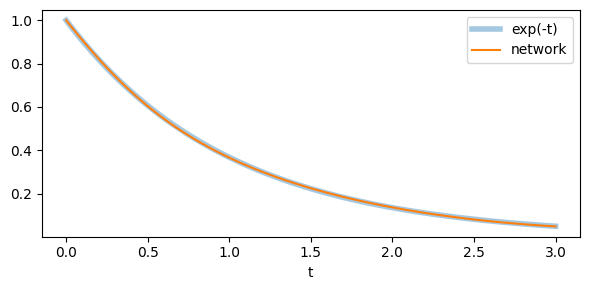

In [8]:
hidden, last = Linear(features=16), Linear(features=1)  # one network, used twice


def network(time):
    return last(Tanh()(hidden(time)))


t_in, t0 = Input("t"), Input("t0")
u = network(t_in)
pinn = Modely("decay", inputs=[t_in, t0], outputs=[Output("u", u)])
pinn.minimize("physics", Gradient(wrt=t_in)(u) + u)  # du/dt + u = 0
pinn.minimize("initial", network(t0), 1.0)  # u(0) = 1
pinn.build()

times = np.random.default_rng(0).uniform(0.0, 3.0, 2000)
data = DataLoader(pinn, source={"t": times, "t0": np.zeros_like(times)})
history = pinn.train(data, epochs=60, batch_size=64, lr=1e-2, printer=None)

grid = np.linspace(0.0, 3.0, 100)
prediction = keras.ops.convert_to_numpy(
    pinn({"t": grid.reshape(-1, 1).astype("float32")})["u"]
).ravel()
print(
    "largest error against exp(-t):", np.abs(prediction - np.exp(-grid)).max().round(4)
)

plt.figure(figsize=(6, 3))
plt.plot(grid, np.exp(-grid), lw=4, alpha=0.4, label="exp(-t)")
plt.plot(grid, prediction, label="network")
plt.xlabel("t")
plt.legend()
plt.tight_layout()

`validate` scores the residual objective too, and `export_onnx` exports a
`Gradient` on TensorFlow (with a batch of 1).

## Summary

| Task | Code |
|---|---|
| Derivative along a window | `DerivativeStep(dt=dt)(init, x)`, `poly_order=` for accuracy |
| Running integral of a window | `IntegrateStep(dt=dt)(init, rate)`, `method="trapezoidal"` |
| Integral, step by step | `Integrate(dt=dt, init=x0)(rate)` in a `ModelyLoop` |
| Derivative, step by step | `Derivative(dt=dt, init=x0)(x)` in a `ModelyLoop` |
| Derivative with respect to an input | `Gradient(wrt=x)(y)`, `order=2` |
| A differential equation as an objective | `model.minimize("physics", Gradient(wrt=t)(u) + u)` |

Next: [Custom layers and functions](12_custom_layers.ipynb).